# 합성곱 신경망(CNN, Convolutional neural network)을 사용한 패션MNIST 분류
* 합성곱 신경망의 전체 구조<br>
<img src="https://drive.google.com/uc?id=1NlV4E0KaH6xI-ikT47wywk9iYacE9yrM" height=240 width=580>

In [ ]:
# 실행마다 동일한 결과를 얻기 위해 케라스에 랜덤 시드 사용
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

## 패션 MNIST 데이터 불러오기

In [ ]:
from tensorflow import keras
from sklearn.model_selection import train_test_split

# 패션 MNIST 데이터셋 가져오기
(train_input, train_target), (test_input, test_target) = \
    keras.datasets.fashion_mnist.load_data()

# reshape + 스케일링: 현재 이미지는 28*28사이즈, 색상은 한가지 색(채널 1)
train_scaled = train_input.reshape(-1, 28, 28, 1) / 255.0

# 훈련 세트에서 검증 세트 나누기
train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

## 합성곱 신경망 만들기

### 1)필터(커널)
* 커널: 입력에 곱하는 가중치<br>
* 필터: 뉴런 개수를 표현할 때 사용하는 용어<br>

<img src="https://drive.google.com/uc?id=1l642M7fHaGB3ZBlPhLTFgC8-1ZHvZnyP" height=340 width=540>

### 2)패딩
*기본: 밸리드 패딩(패딩없음)<br>
*padding='same' : 0으로 채운 패딩 생성<br>
<img src="https://drive.google.com/uc?id=1JOQygAhnDTkS94li0YMtkCbq5EtnolXJ" height=240 width=540>



In [ ]:
model = keras.Sequential()

In [ ]:
# 필터(커널): 32개, 커널사이즈: 3(2차원에서는 3*3과 동일), 패딩: same
model.add(keras.layers.Conv2D(32, kernel_size=3, activation='relu',
                              padding='same', input_shape=(28,28,1)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# 풀링: 최대 풀링(MaxPooling)
model.add(keras.layers.MaxPooling2D(2))

In [ ]:
# 필터(커널): 64개, 커널사이즈: 3*3, 패딩: same
# 풀링: 최대 풀링(MaxPooling)
model.add(keras.layers.Conv2D(64, kernel_size=(3,3), activation='relu',
                              padding='same'))
model.add(keras.layers.MaxPooling2D(2))

In [ ]:
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(100, activation='relu'))
model.add(keras.layers.Dropout(0.4)) # 과적합 방지: 학습할 때 입력값 중 약 40%를 무작위로 골라 0으로 만듦
model.add(keras.layers.Dense(10, activation='softmax'))

### 3)파라미터 계산 방법
$\text{파라미터 수}
= (\text{커널 높이}\times\text{커널 너비}\times\text{입력 채널 수}+1(편향))
\times\text{필터 수}$<br>
* 첫번째 Conv2D: $(3\times3\times1+1)\times32
=\boxed{320}$
* 두번째 Conv2D: $(3\times3\times32+1)\times64
=289\times64
=\boxed{18,496}$
* Dense 에서 파라미터 계산하는 방법은 인공신경망에서 배운 방법 그대로 활용

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       313,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,526 (1.27 MB)

 Trainable params: 333,526 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

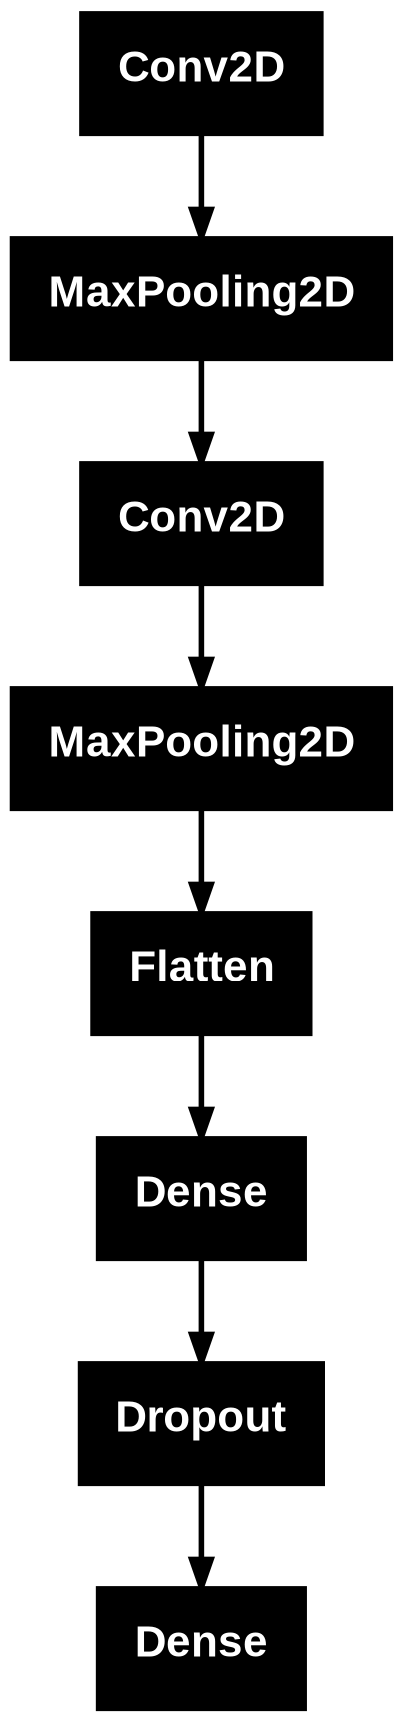

In [ ]:
keras.utils.plot_model(model)

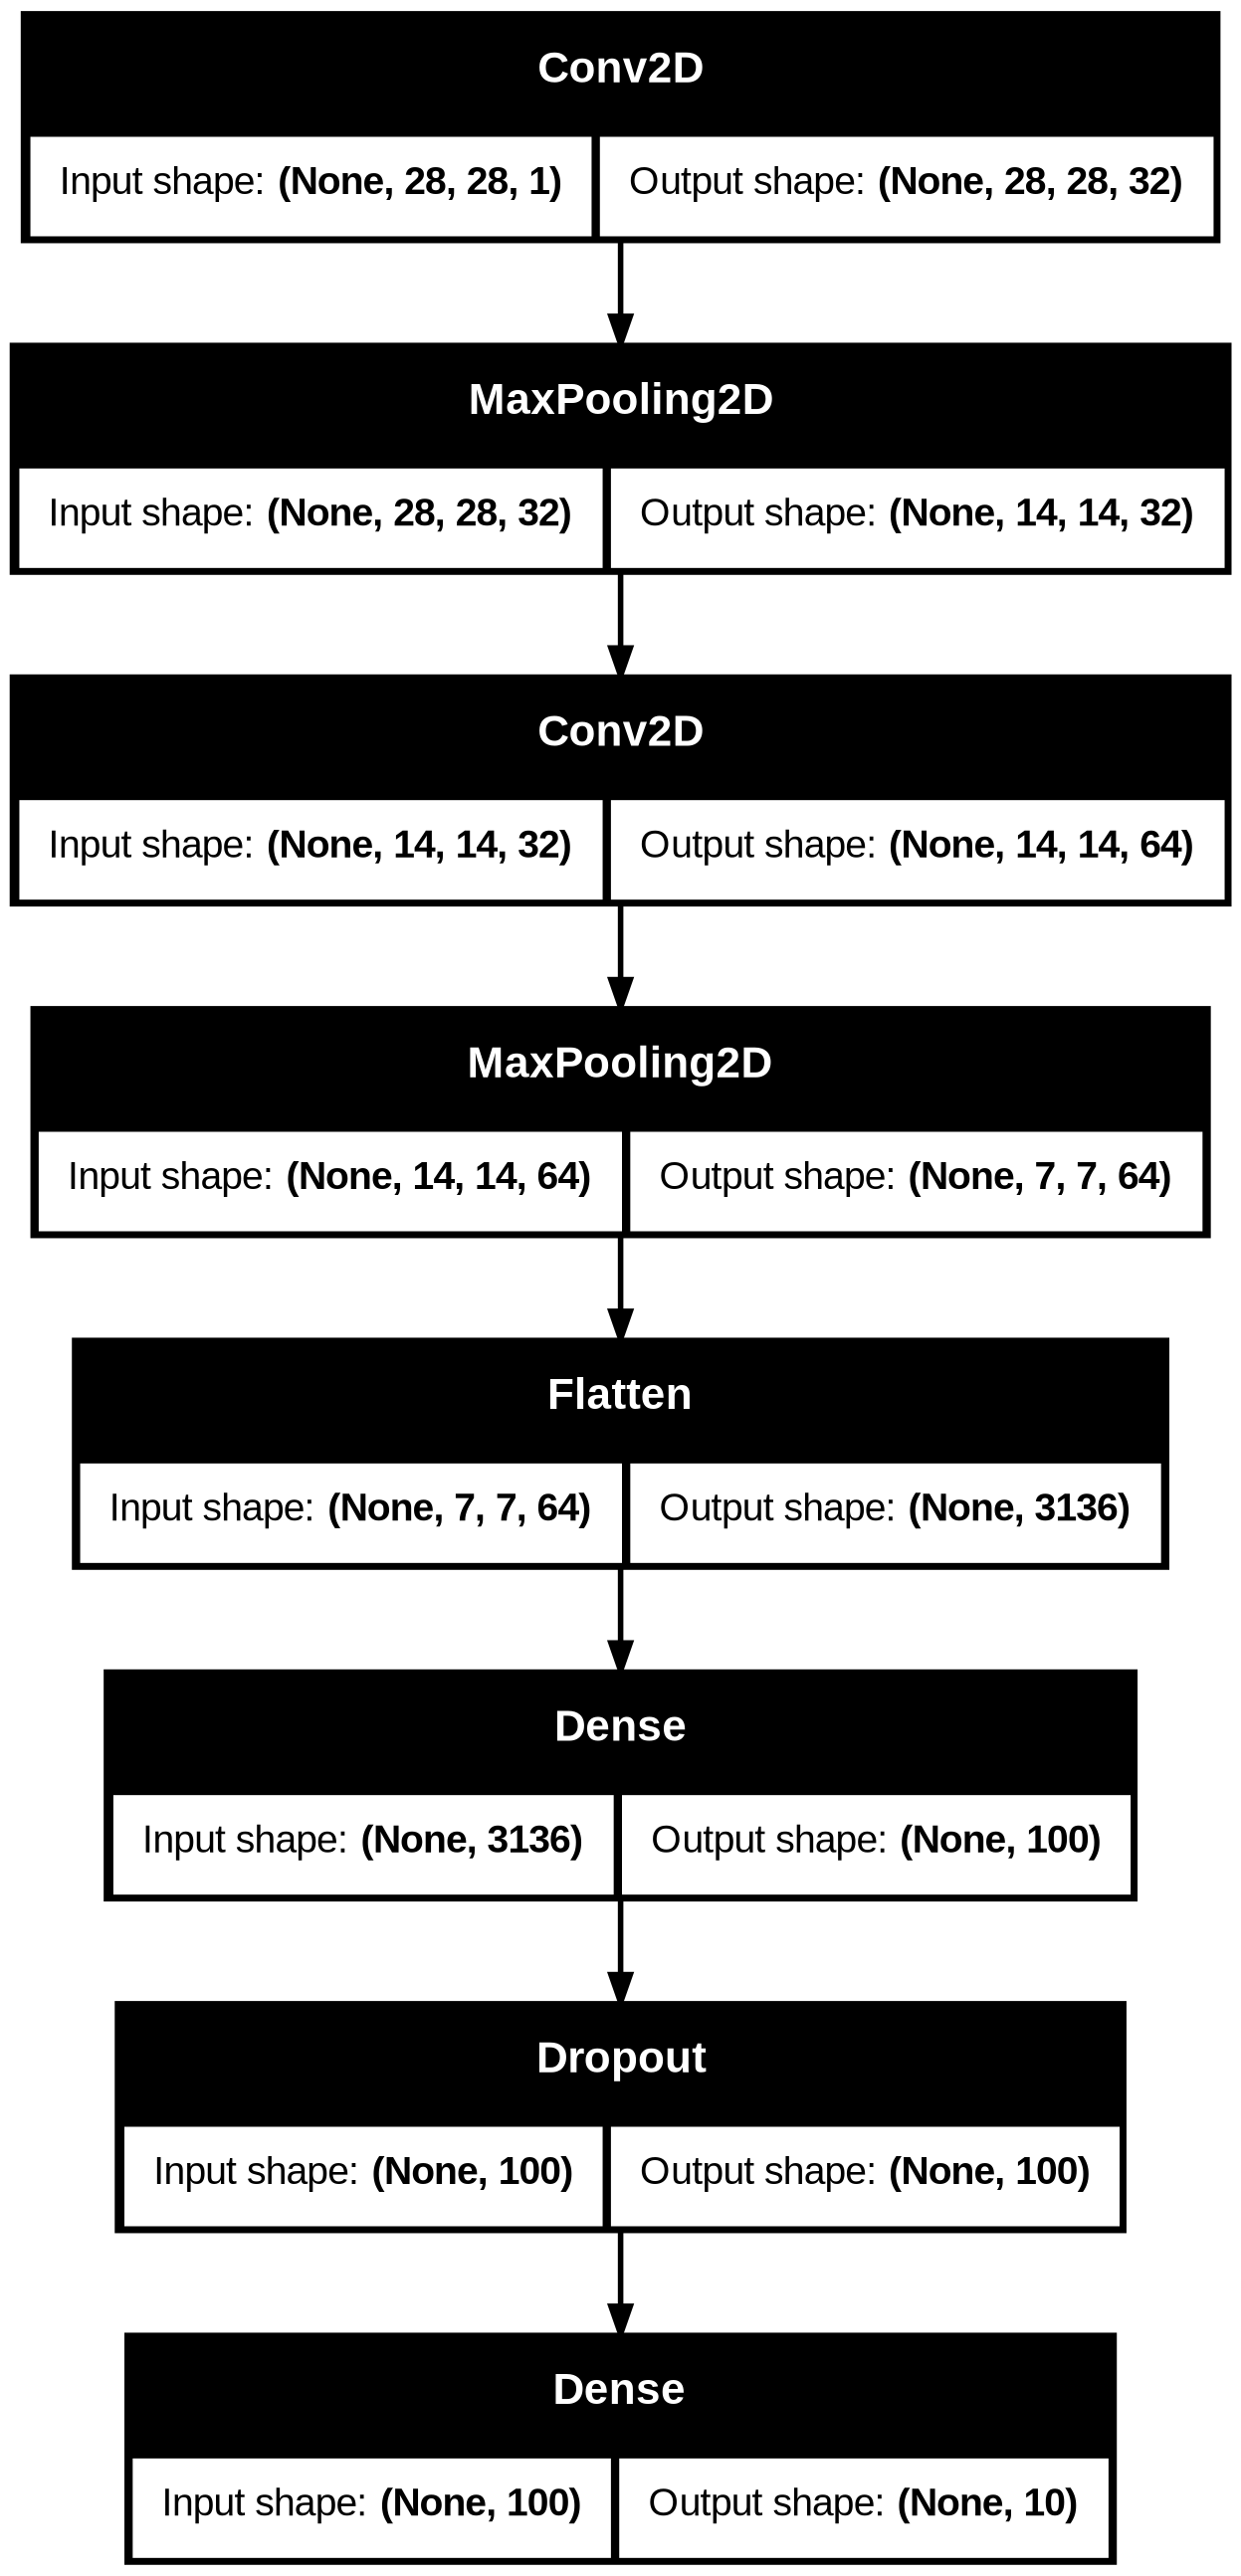

In [ ]:
keras.utils.plot_model(model, show_shapes=True)

## 모델 컴파일과 훈련

In [ ]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

checkpoint_cb = keras.callbacks.ModelCheckpoint('best-cnn-model.keras',
                                                save_best_only=True)
early_stopping_cb = keras.callbacks.EarlyStopping(patience=2,
                                                  restore_best_weights=True)

history = model.fit(train_scaled, train_target, epochs=20,
                    validation_data=(val_scaled, val_target),
                    callbacks=[checkpoint_cb, early_stopping_cb])

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - accuracy: 0.8188 - loss: 0.5113 - val_accuracy: 0.8828 - val_loss: 0.3184
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8797 - loss: 0.3367 - val_accuracy: 0.8929 - val_loss: 0.2785
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8949 - loss: 0.2896 - val_accuracy: 0.9085 - val_loss: 0.2464
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9062 - loss: 0.2565 - val_accuracy: 0.9107 - val_loss: 0.2437
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9146 - loss: 0.2362 - val_accuracy: 0.9122 - val_loss: 0.2363
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9197 - loss: 0.2151 - val_accuracy: 0.9166 - val_loss: 0.2301
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9263 - loss: 0.2000 - val_accuracy: 0.9162 - val_loss: 0.2335
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9321 - loss: 0.1795 -

In [ ]:
import matplotlib.pyplot as plt

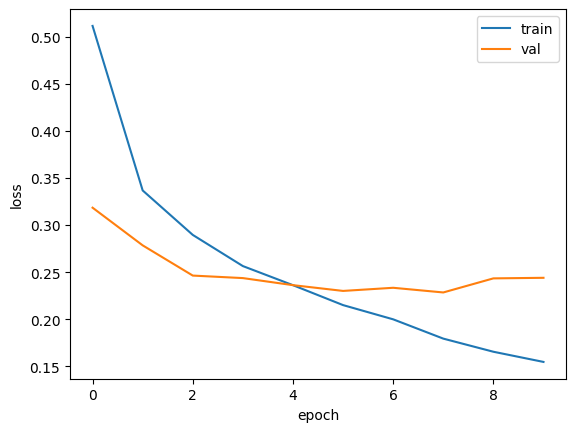

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9177 - loss: 0.2285


[0.22850419580936432, 0.9176666736602783]

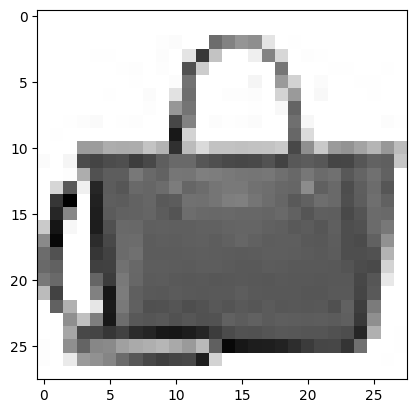

In [ ]:
plt.imshow(val_scaled[0].reshape(28, 28), cmap='gray_r')
plt.show()

In [ ]:
preds = model.predict(val_scaled[0:1])
print(preds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[5.88489690e-21 2.86580369e-30 8.13289214e-23 2.79516037e-22
  6.89859390e-20 1.41989898e-23 1.29094225e-20 2.10170539e-21
  1.00000000e+00 1.99616164e-24]]


In [ ]:
classes = ['티셔츠', '바지', '스웨터', '드레스', '코트',
           '샌달', '셔츠', '스니커즈', '가방', '앵클 부츠']

In [ ]:
import numpy as np
print(classes[np.argmax(preds)])

가방


In [ ]:
test_scaled = test_input.reshape(-1, 28, 28, 1) / 255.0

In [ ]:
model.evaluate(test_scaled, test_target)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9117 - loss: 0.2643


[0.2642761766910553, 0.9117000102996826]